In [2]:
# Cell A — what is actually in the batch 1 frames folder
from pathlib import Path
import os, json
import pandas as pd
import numpy as np
from PIL import Image
from tqdm.auto import tqdm

HOME     = Path.home()
ARCH     = HOME / "dataset_arch" / "SignLanguage"
B1_ROOT  = ARCH / "frames"
REPORTS  = HOME / "work" / "signlanguage" / "reports"
REPORTS.mkdir(parents=True, exist_ok=True)

rows = []
for cat_dir in sorted(p for p in B1_ROOT.iterdir() if p.is_dir()):
    for clip_dir in sorted(p for p in cat_dir.iterdir() if p.is_dir()):
        imgs = sorted(clip_dir.glob("*.png")) or sorted(clip_dir.glob("*.jpg"))
        rows.append({
            "category": cat_dir.name,
            "clip":     clip_dir.name,
            "n_frames": len(imgs),
            "ext":      imgs[0].suffix if imgs else None,
            "first":    str(imgs[0]) if imgs else None,
            "bytes":    sum(f.stat().st_size for f in imgs),
        })

b1 = pd.DataFrame(rows)
print(f"categories : {b1.category.nunique()}")
print(f"clips      : {len(b1)}")
print(f"empty clips: {int((b1.n_frames == 0).sum())}")
print(f"total frames: {int(b1.n_frames.sum()):,}")
print(f"total size : {b1.bytes.sum()/1e9:.1f} GB")

print("\n" + "="*70); print("PER CATEGORY"); print("="*70)
print(b1.groupby("category").agg(
        clips=("clip", "count"),
        frames=("n_frames", "sum"),
        mean_frames=("n_frames", "mean"),
        min_frames=("n_frames", "min"),
        max_frames=("n_frames", "max"),
        gb=("bytes", lambda s: s.sum()/1e9)).round(1).to_string())

# image size and format — sample 40 clips
print("="*70); print("IMAGE SIZE AND FORMAT"); print("="*70)
sizes = []
sub = b1.dropna(subset=["first"]).sample(min(40, len(b1)), random_state=0)
for f in sub["first"]:
    im = Image.open(f)
    sizes.append({"size": f"{im.width}x{im.height}", "mode": im.mode, "fmt": im.format})
print(pd.DataFrame(sizes).value_counts().to_string())

print("\n" + "="*70); print("THE EMPTY CLIP"); print("="*70)
print(b1[b1.n_frames == 0][["category", "clip"]].to_string(index=False))

b1.to_csv(REPORTS / "batch1_frames.csv", index=False)
print(f"\nsaved -> {REPORTS / 'batch1_frames.csv'}")

categories : 7
clips      : 1054
empty clips: 1
total frames: 686,845
total size : 598.9 GB

PER CATEGORY
                        clips  frames  mean_frames  min_frames  max_frames     gb
category                                                                         
1_worldcooking            254  102769        404.6           0         701  146.6
2_salt                    163  131712        808.0         472        1429   98.8
3_molecular_gastronomy    130   62358        479.7         260         802   91.0
4_steak                   164  127715        778.8         373        1742   81.2
5_chanthaburi_seafood      70   28783        411.2         248         753   41.8
6_leaf                    154  119289        774.6          90        2340   71.8
8_chicken                 119  114219        959.8         473        1667   67.7
IMAGE SIZE AND FORMAT
size       mode  fmt
1920x1080  RGB   PNG    40

THE EMPTY CLIP
      category               clip
1_worldcooking .ipynb_checkpoints

s

In [3]:
# Cell B — look for the original fps
rep = ARCH / "frame_inspection_report.json"
print(f"{rep}  exists: {rep.exists()}")

if rep.exists():
    d = json.loads(rep.read_text())
    print(f"type: {type(d)}")
    if isinstance(d, dict):
        print(f"keys ({len(d)}): {list(d)[:15]}")
        k = list(d)[0]
        print(f"\nexample entry '{k}':")
        print(json.dumps(d[k], indent=2)[:900])
    elif isinstance(d, list):
        print(f"{len(d)} entries; first:")
        print(json.dumps(d[0], indent=2)[:900])

# also check whether the source videos still exist
mp4 = ARCH / "mp4_from_bag"
print(f"\n{mp4}  exists: {mp4.exists()}")
if mp4.exists():
    for p in sorted(mp4.iterdir())[:8]:
        print("   ", p.name)

/home/soehn/dataset_arch/SignLanguage/frame_inspection_report.json  exists: True
type: <class 'list'>
1053 entries; first:
{
  "clip": "/home/soehn/work/frames/1_worldcooking/1_worldcooking_clip_001",
  "relative_clip": "1_worldcooking/1_worldcooking_clip_001",
  "frame_count": 340,
  "width": 1920,
  "height": 1080,
  "duration_if_120fps_sec": 2.833,
  "status": "ok"
}

/home/soehn/dataset_arch/SignLanguage/mp4_from_bag  exists: True
    1_worldcooking


real clips: 1053

BATCH 1 — one clip per category

1_worldcooking_clip_001   340 frames


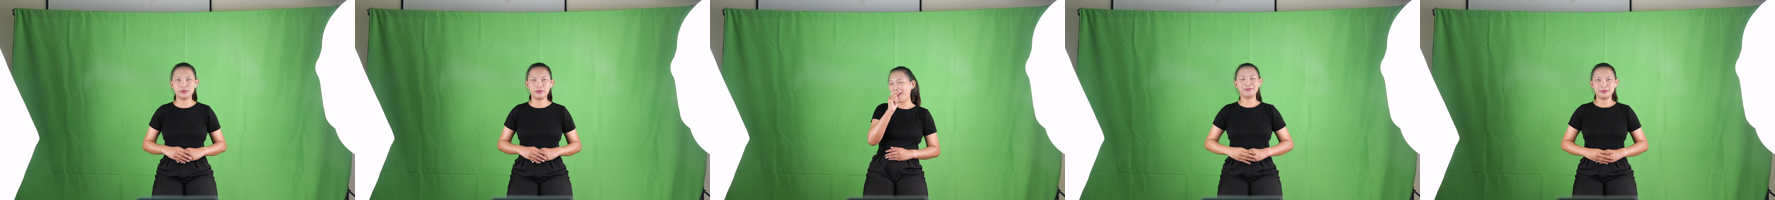

   full frame  |  what the centre crop keeps:


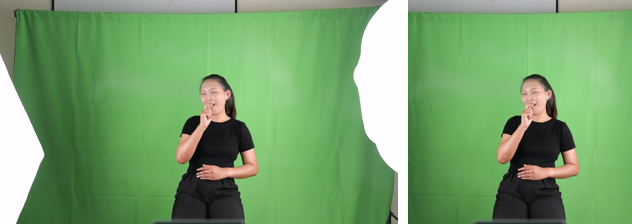


2_salt_clip_001   711 frames


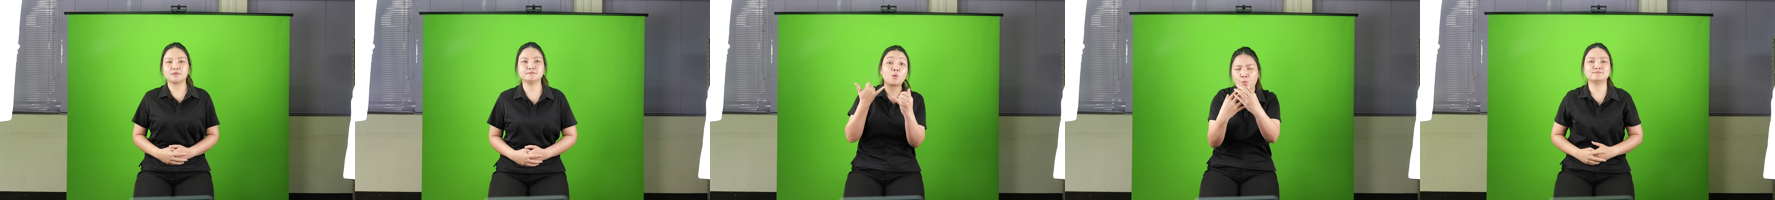

   full frame  |  what the centre crop keeps:


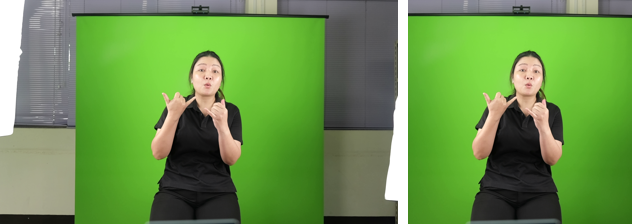


3_molecular_gastronomy_clip_001   405 frames


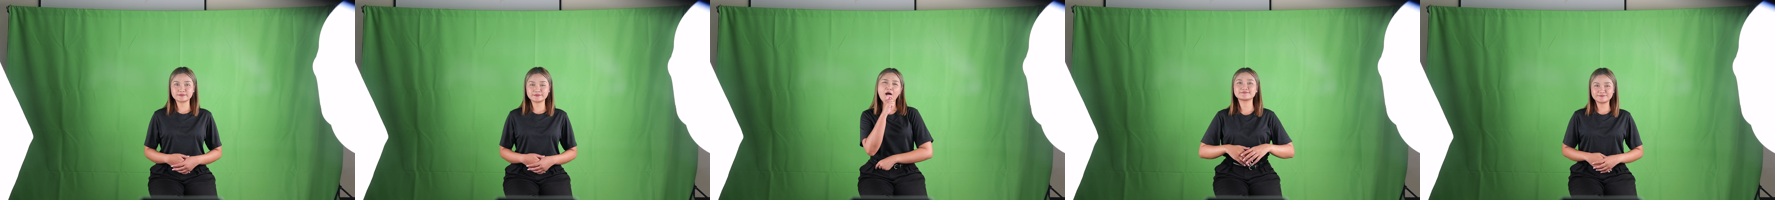

   full frame  |  what the centre crop keeps:


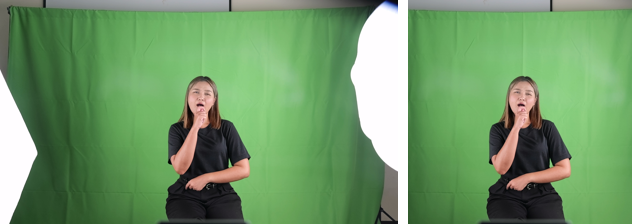


4_steak_clip_001   1099 frames


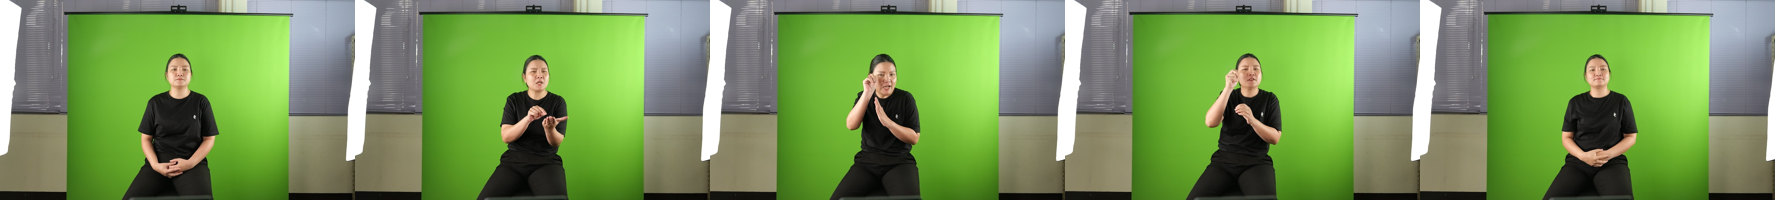

   full frame  |  what the centre crop keeps:


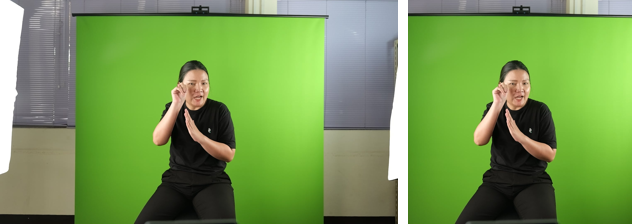


5_chanthaburi_seafood_clip_001   376 frames


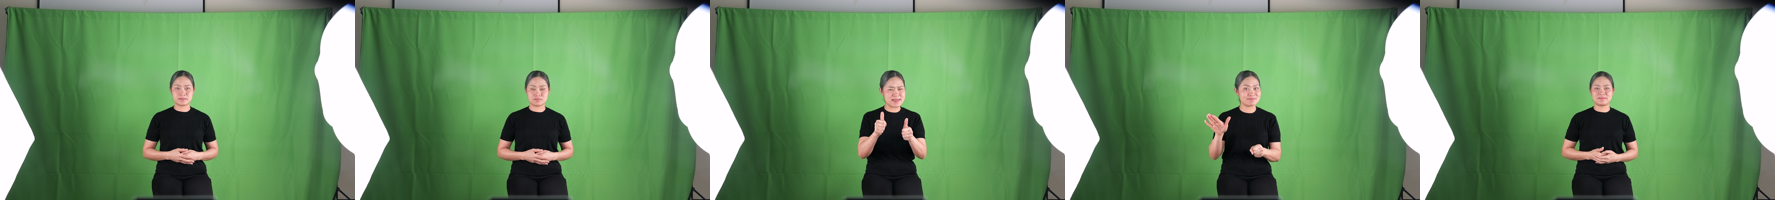

   full frame  |  what the centre crop keeps:


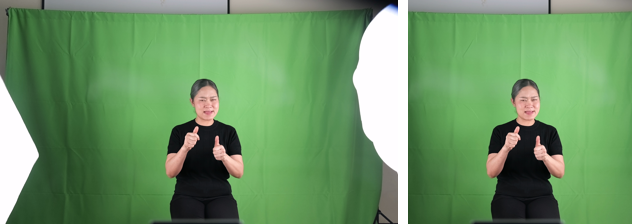


6_leaf_clip_001   164 frames


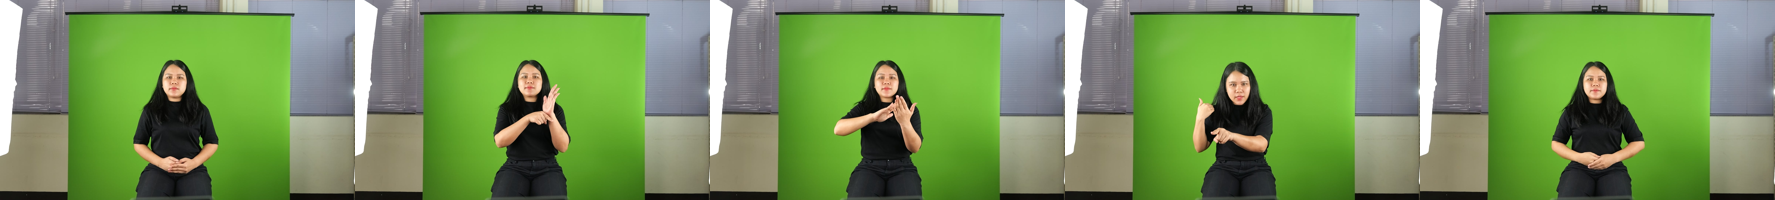

   full frame  |  what the centre crop keeps:


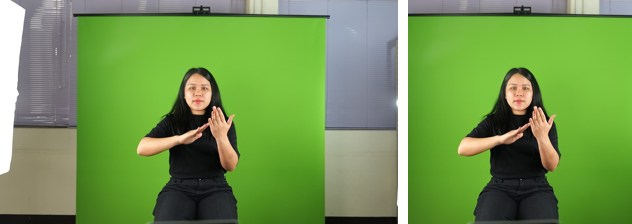


8_chicken_clip_001   1394 frames


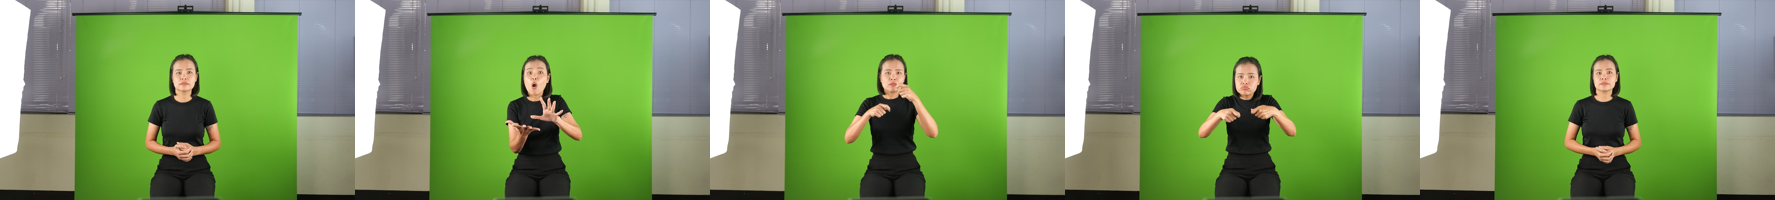

   full frame  |  what the centre crop keeps:


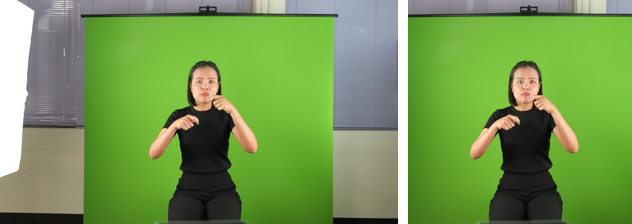


BATCH 2 — for comparison

b2_A_01_0001


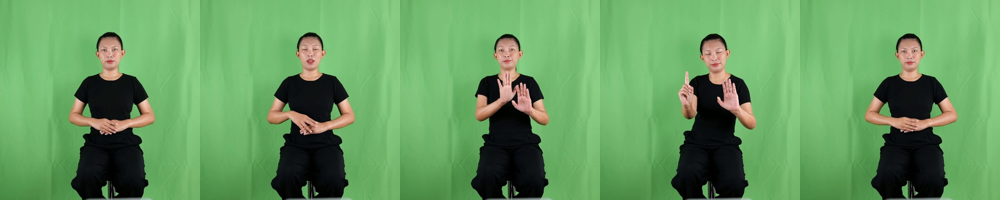


b2_B_09_0150


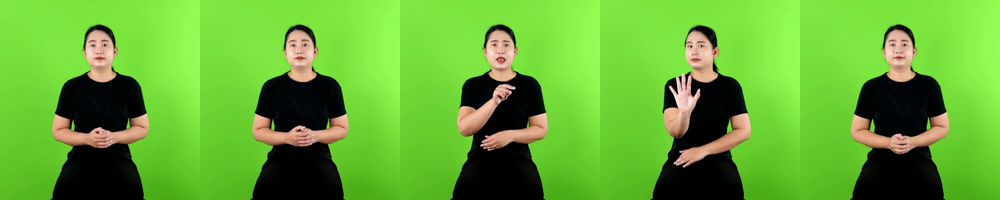

In [5]:
# Cell C — look at batch 1 frames, and compare with batch 2
from IPython.display import display

b1 = b1[b1["clip"] != ".ipynb_checkpoints"].copy()     # drop the Jupyter folder
b1 = b1[b1["n_frames"] > 0]
print(f"real clips: {len(b1)}")

def strip(clip_dir, n=5, h=200):
    files = sorted(Path(clip_dir).glob("*.png")) or sorted(Path(clip_dir).glob("*.jpg"))
    if not files:
        return None
    idx = np.linspace(0, len(files) - 1, n).astype(int)
    ims = [Image.open(files[i]).convert("RGB") for i in idx]
    ims = [im.resize((int(im.width * h / im.height), h)) for im in ims]
    out = Image.new("RGB", (sum(i.width for i in ims), h), "white")
    x = 0
    for im in ims:
        out.paste(im, (x, 0)); x += im.width
    return out

def crop_preview(clip_dir, h=224):
    """Left = full frame, right = what the centre crop keeps."""
    files = sorted(Path(clip_dir).glob("*.png")) or sorted(Path(clip_dir).glob("*.jpg"))
    im = Image.open(files[len(files)//2]).convert("RGB")
    w, hh = im.size
    s = min(w, hh)
    crop = im.crop(((w-s)//2, (hh-s)//2, (w+s)//2, (hh+s)//2)).resize((h, h))
    full = im.resize((int(w * h / hh), h))
    out = Image.new("RGB", (full.width + crop.width + 10, h), "white")
    out.paste(full, (0, 0)); out.paste(crop, (full.width + 10, 0))
    return out

print("\n" + "="*60); print("BATCH 1 — one clip per category"); print("="*60)
for cat, g in b1.groupby("category"):
    r = g.iloc[0]
    d = Path(r["first"]).parent
    print(f"\n{r['clip']}   {r['n_frames']} frames")
    display(strip(d))
    print("   full frame  |  what the centre crop keeps:")
    display(crop_preview(d))

print("\n" + "="*60); print("BATCH 2 — for comparison"); print("="*60)
b2_root = ARCH / "frames_batch2_30fps"
for cid in ["b2_A_01_0001", "b2_B_09_0150"]:
    d = b2_root / cid
    if d.exists():
        print(f"\n{cid}")
        display(strip(d))

In [7]:
# Cell D — read the real fps out of the source .bag files
from rosbags.rosbag1 import Reader as Reader1

TSL_ROOT    = HOME / "work" / "tsl"
IMAGE_TOPIC = "/device_0/sensor_0/Color_0/image/data"

cats = sorted(p for p in TSL_ROOT.iterdir() if p.is_dir())
print("bag folders:")
for c in cats:
    print(f"   {c.name:26s} {len(sorted(c.glob('*.bag'))):4d} bags")

print("\n" + "="*74); print("TRUE FRAME RATE (from bag timestamps)"); print("="*74)
res = []
for c in cats:
    for bag in sorted(c.glob("*-m.bag"))[:3]:        # 3 bags per category
        try:
            with Reader1(bag) as rd:
                conn = [x for x in rd.connections if x.topic == IMAGE_TOPIC]
                if not conn:
                    print(f"  {c.name}/{bag.name}: topic missing. topics = "
                          f"{[x.topic for x in rd.connections][:4]}")
                    continue
                ts = [t for _, t, _ in rd.messages(connections=conn)]
            n, secs = len(ts), (ts[-1] - ts[0]) / 1e9
            fps = (n - 1) / secs if secs > 0 else None
            res.append({"category": c.name, "bag": bag.name,
                        "frames": n, "seconds": round(secs, 2), "fps": round(fps, 2)})
            print(f"  {c.name:26s} {bag.name:12s} {n:5d} frames {secs:7.2f}s -> {fps:7.2f} fps")
        except Exception as e:
            print(f"  {c.name}/{bag.name}: {type(e).__name__}: {e}")

bagfps = pd.DataFrame(res)
if len(bagfps):
    print("\n" + "="*74)
    print(bagfps.groupby("category")[["frames","seconds","fps"]].mean().round(2).to_string())
    print(f"\nOVERALL MEDIAN FPS: {bagfps.fps.median():.2f}")

bag folders:
   .ipynb_checkpoints            0 bags
   1_worldcooking              253 bags
   2_salt                      163 bags
   3_molecular_gastronomy      130 bags
   4_steak                     164 bags
   5_chanthaburi_seafood        70 bags
   6_leaf                      154 bags
   8_chiken                    119 bags
   annotations                   0 bags
   checkpoints                   0 bags
   targets                       0 bags

TRUE FRAME RATE (from bag timestamps)
  1_worldcooking             1-m.bag        340 frames   10.05s ->   33.74 fps
  1_worldcooking             10-m.bag       383 frames   11.08s ->   34.47 fps
  1_worldcooking             100-m.bag      442 frames   11.47s ->   38.44 fps
  2_salt                     1-m.bag        711 frames   16.08s ->   44.17 fps
  2_salt                     10-m.bag       694 frames   16.17s ->   42.85 fps
  2_salt                     100-m.bag      708 frames   11.06s ->   63.95 fps
  3_molecular_gastronomy     1-m.b

In [8]:
# Cell F — are the timestamps regular, and do bags match the extracted folders?
from rosbags.rosbag1 import Reader as Reader1

TSL_ROOT    = HOME / "work" / "tsl"
IMAGE_TOPIC = "/device_0/sensor_0/Color_0/image/data"

# map bag folder name -> frames folder name (note the typo 8_chiken vs 8_chicken)
BAGDIR_TO_FRAMEDIR = {
    "1_worldcooking": "1_worldcooking", "2_salt": "2_salt",
    "3_molecular_gastronomy": "3_molecular_gastronomy", "4_steak": "4_steak",
    "5_chanthaburi_seafood": "5_chanthaburi_seafood", "6_leaf": "6_leaf",
    "8_chiken": "8_chicken",
}

rows = []
for bagdir, framedir in BAGDIR_TO_FRAMEDIR.items():
    d = TSL_ROOT / bagdir
    if not d.is_dir():
        continue
    for bag in sorted(d.glob("*-m.bag"))[:4]:
        num = int(bag.stem.split("-")[0])
        try:
            with Reader1(bag) as rd:
                conn = [x for x in rd.connections if x.topic == IMAGE_TOPIC]
                ts = np.array([t for _, t, _ in rd.messages(connections=conn)])
        except Exception as e:
            print(f"  {bagdir}/{bag.name}: {e}"); continue

        gaps = np.diff(ts) / 1e9                      # seconds between frames
        clip_dir = B1_ROOT / framedir / f"{framedir}_clip_{num:03d}"
        n_png = len(list(clip_dir.glob("*.png"))) if clip_dir.is_dir() else -1

        rows.append({
            "cat": framedir, "bag": bag.name,
            "bag_frames": len(ts), "png_frames": n_png,
            "span_s": round((ts[-1]-ts[0])/1e9, 2),
            "avg_fps": round((len(ts)-1)/((ts[-1]-ts[0])/1e9), 1),
            "gap_median_ms": round(np.median(gaps)*1000, 1),
            "gap_min_ms": round(gaps.min()*1000, 1),
            "gap_max_ms": round(gaps.max()*1000, 1),
            "fps_from_median_gap": round(1/np.median(gaps), 1),
            "big_gaps": int((gaps > 3*np.median(gaps)).sum()),
        })

f = pd.DataFrame(rows)
pd.set_option("display.width", 200)

print("="*110); print("BAG vs EXTRACTED PNG FRAME COUNTS"); print("="*110)
print(f[["cat","bag","bag_frames","png_frames","span_s","avg_fps"]].to_string(index=False))
print(f"\nmismatched (bag != png): {int((f['bag_frames'] != f['png_frames']).sum())} of {len(f)}")

print("\n" + "="*110); print("IS THE FRAME RATE STEADY INSIDE A CLIP?"); print("="*110)
print(f[["cat","bag","avg_fps","fps_from_median_gap",
         "gap_median_ms","gap_min_ms","gap_max_ms","big_gaps"]].to_string(index=False))

print("""
HOW TO READ THIS
  gap_median_ms ~= gap_max_ms, big_gaps = 0
      -> steady recording. A per-clip stride on the existing PNGs is fine.
  gap_max_ms much larger than gap_median_ms, big_gaps > 0
      -> frames were dropped unevenly. We must pick frames by timestamp,
         which means re-extracting from the .bag files.
  avg_fps much lower than fps_from_median_gap
      -> the camera ran fast but lost long stretches.
""")

BAG vs EXTRACTED PNG FRAME COUNTS
                   cat       bag  bag_frames  png_frames  span_s  avg_fps
        1_worldcooking   1-m.bag         340         340   10.05     33.7
        1_worldcooking  10-m.bag         383         383   11.08     34.5
        1_worldcooking 100-m.bag         442         442   11.47     38.4
        1_worldcooking 101-m.bag         548         548   14.40     38.0
                2_salt   1-m.bag         711         711   16.08     44.2
                2_salt  10-m.bag         694         694   16.17     42.8
                2_salt 100-m.bag         708         708   11.06     64.0
                2_salt 101-m.bag         544         544    8.61     63.1
3_molecular_gastronomy   1-m.bag         405         405    9.83     41.1
3_molecular_gastronomy  10-m.bag         378         378    9.11     41.4
3_molecular_gastronomy 100-m.bag         661         661   20.03     33.0
3_molecular_gastronomy 101-m.bag         458         458   13.32     34.3
    

In [9]:
# Cell F — per-clip: bag vs PNG, and are timestamps regular?
from pathlib import Path
import numpy as np, pandas as pd
from rosbags.rosbag1 import Reader as Reader1

HOME     = Path.home()
ARCH     = HOME / "dataset_arch" / "SignLanguage"
TSL      = HOME / "work" / "tsl"
B1       = ARCH / "frames"
TOPIC    = "/device_0/sensor_0/Color_0/image/data"

BAG2FRAME = {"1_worldcooking":"1_worldcooking", "2_salt":"2_salt",
             "3_molecular_gastronomy":"3_molecular_gastronomy", "4_steak":"4_steak",
             "5_chanthaburi_seafood":"5_chanthaburi_seafood", "6_leaf":"6_leaf",
             "8_chiken":"8_chicken"}

rows = []
for bagdir, framedir in BAG2FRAME.items():
    d = TSL / bagdir
    if not d.is_dir():
        print(f"missing {d}"); continue
    for bag in sorted(d.glob("*-m.bag"))[:5]:          # 5 per category
        n = int(bag.stem.split("-")[0])
        try:
            with Reader1(bag) as rd:
                conn = [x for x in rd.connections if x.topic == TOPIC]
                ts = np.array([t for _, t, _ in rd.messages(connections=conn)])
        except Exception as e:
            print(f"{bagdir}/{bag.name}: {e}"); continue

        gaps = np.diff(ts) / 1e9
        med  = float(np.median(gaps))
        clip = B1 / framedir / f"{framedir}_clip_{n:03d}"
        png  = len(list(clip.glob("*.png"))) if clip.is_dir() else -1

        rows.append({
            "cat": framedir, "clip": n,
            "bag_frames": len(ts), "png_frames": png,
            "match": len(ts) == png,
            "span_s": round((ts[-1]-ts[0])/1e9, 2),
            "avg_fps": round((len(ts)-1)/((ts[-1]-ts[0])/1e9), 1),
            "steady_fps": round(1/med, 1),
            "gap_med_ms": round(med*1000, 1),
            "gap_max_ms": round(gaps.max()*1000, 1),
            "big_gaps": int((gaps > 3*med).sum()),
        })

f = pd.DataFrame(rows)
pd.set_option("display.width", 220)

print("="*100); print("1. DO BAG AND PNG FRAME COUNTS MATCH, PER CLIP?"); print("="*100)
print(f[["cat","clip","bag_frames","png_frames","match"]].to_string(index=False))
print(f"\nmatching: {int(f['match'].sum())} of {len(f)}")

print("\n" + "="*100); print("2. IS THE FRAME RATE STEADY INSIDE EACH CLIP?"); print("="*100)
print(f[["cat","clip","avg_fps","steady_fps","gap_med_ms","gap_max_ms","big_gaps"]].to_string(index=False))
print("""
  avg_fps close to steady_fps, big_gaps = 0  -> steady. Subsample the PNGs. Cheap.
  avg_fps much lower, big_gaps > 0           -> frames dropped unevenly.
                                                Must pick frames by timestamp.
""")

print("="*100); print("3. WHAT IS IN mp4_from_bag?"); print("="*100)
m = ARCH / "mp4_from_bag"
print(f"{m}  exists: {m.is_dir()}")
if m.is_dir():
    items = sorted(m.iterdir())
    print(f"{len(items)} entries; first 10:")
    for p in items[:10]:
        print(f"   {p.name}   {'dir' if p.is_dir() else f'{p.stat().st_size/1e6:.1f} MB'}")

1. DO BAG AND PNG FRAME COUNTS MATCH, PER CLIP?
                   cat  clip  bag_frames  png_frames  match
        1_worldcooking     1         340         340   True
        1_worldcooking    10         383         383   True
        1_worldcooking   100         442         442   True
        1_worldcooking   101         548         548   True
        1_worldcooking   102         446         446   True
                2_salt     1         711         711   True
                2_salt    10         694         694   True
                2_salt   100         708         708   True
                2_salt   101         544         544   True
                2_salt   102         662         662   True
3_molecular_gastronomy     1         405         405   True
3_molecular_gastronomy    10         378         378   True
3_molecular_gastronomy   100         661         661   True
3_molecular_gastronomy   101         458         458   True
3_molecular_gastronomy   102         359         359

In [12]:
# Cell G — measure the frame rate of every batch 1 clip
from rosbags.rosbag1 import Reader as Reader1
from tqdm.auto import tqdm

TOPIC = "/device_0/sensor_0/Color_0/image/data"
BAG2FRAME = {"1_worldcooking":"1_worldcooking", "2_salt":"2_salt",
             "3_molecular_gastronomy":"3_molecular_gastronomy", "4_steak":"4_steak",
             "5_chanthaburi_seafood":"5_chanthaburi_seafood", "6_leaf":"6_leaf",
             "8_chiken":"8_chicken"}

bags = []
for bagdir, framedir in BAG2FRAME.items():
    for bag in sorted((TSL / bagdir).glob("*-m.bag")):
        bags.append((framedir, int(bag.stem.split("-")[0]), bag))
print(f"{len(bags)} bags to read")

rows = []
for framedir, n, bag in tqdm(bags):
    try:
        with Reader1(bag) as rd:
            conn = [c for c in rd.connections if c.topic == TOPIC]
            cnt  = sum(c.msgcount for c in conn)              # from the index, fast
            dur  = rd.duration / 1e9 if rd.duration else None
        fps = (cnt - 1) / dur if dur and cnt > 1 else None
        clip = B1 / framedir / f"{framedir}_clip_{n:03d}"
        png  = len(list(clip.glob("*.png"))) if clip.is_dir() else -1
        rows.append({"cat": framedir, "clip": n,
                     "cid": f"b1_{framedir}_{n:04d}",
                     "bag_frames": cnt, "png_frames": png,
                     "seconds": round(dur, 2) if dur else None,
                     "fps": round(fps, 2) if fps else None,
                     "path": str(clip)})
    except Exception as e:
        rows.append({"cat": framedir, "clip": n, "cid": f"b1_{framedir}_{n:04d}",
                     "bag_frames": -1, "png_frames": -1, "seconds": None,
                     "fps": None, "path": "", "error": f"{type(e).__name__}: {e}"})

b1fps = pd.DataFrame(rows)
b1fps.to_csv(REPORTS / "batch1_fps.csv", index=False)
print(f"\nsaved -> {REPORTS / 'batch1_fps.csv'}")

ok = b1fps[b1fps["fps"].notna()]
print(f"\nread ok: {len(ok)} of {len(b1fps)}")
print(f"bag vs png mismatches: {int((ok['bag_frames'] != ok['png_frames']).sum())}")

print("\n" + "="*70); print("FRAME RATE DISTRIBUTION"); print("="*70)
bins   = [0, 15, 20, 25, 28, 32, 45, 55, 75, 999]
labels = ["<15","15-20","20-25","25-28","28-32","32-45","45-55","55-75",">75"]
ok = ok.assign(band=pd.cut(ok["fps"], bins=bins, labels=labels))
print(ok["band"].value_counts().sort_index().to_string())

print("\n" + "="*70); print("HOW MANY CLIPS ARE BELOW 30 FPS?"); print("="*70)
for thr in [25, 28, 30]:
    n = int((ok["fps"] < thr).sum())
    print(f"  below {thr} fps: {n:4d} clips  ({100*n/len(ok):5.1f}%)")

print("\n" + "="*70); print("BY CATEGORY"); print("="*70)
print(ok.groupby("cat")["fps"].describe()[["count","min","50%","max"]].round(1).to_string())

print("\n" + "="*70); print("THE SLOW CLIPS"); print("="*70)
slow = ok[ok["fps"] < 28].sort_values("fps")
print(f"{len(slow)} clips under 28 fps")
if len(slow):
    print(slow.groupby("cat").size().to_string())
    print("\nslowest 15:")
    print(slow.head(15)[["cat","clip","fps","png_frames","seconds"]].to_string(index=False))

1053 bags to read


  0%|          | 0/1053 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [13]:
# Cell G-diag — time ONE bag and see what the reader gives us
import time
from rosbags.rosbag1 import Reader as Reader1

TOPIC = "/device_0/sensor_0/Color_0/image/data"
bag = sorted((TSL / "1_worldcooking").glob("*-m.bag"))[0]
print(f"bag  : {bag.name}")
print(f"size : {bag.stat().st_size/1e9:.2f} GB")

t0 = time.time()
with Reader1(bag) as rd:
    t_open = time.time() - t0
    print(f"\nopened in {t_open:.1f}s")

    print("\navailable attributes:")
    for a in ["duration", "start_time", "end_time", "message_count"]:
        print(f"   rd.{a:14s} = {getattr(rd, a, 'NOT AVAILABLE')}")

    conn = [c for c in rd.connections if c.topic == TOPIC]
    print(f"\nconnections on the colour topic: {len(conn)}")
    for c in conn:
        print(f"   msgcount = {getattr(c, 'msgcount', 'NOT AVAILABLE')}")

print(f"\ntotal: {time.time()-t0:.1f}s for one bag")
print(f"estimate for 1053 bags: {(time.time()-t0)*1053/60:.0f} minutes")

bag  : 1-m.bag
size : 0.94 GB

opened in 0.1s

available attributes:
   rd.duration       = 10046886700
   rd.start_time     = 1
   rd.end_time       = 10046886701
   rd.message_count  = 2060

connections on the colour topic: 1
   msgcount = 340

total: 0.1s for one bag
estimate for 1053 bags: 1 minutes


In [14]:
# Cell G-fast — first and last timestamp only
def clip_fps(bag_path, n_png):
    with Reader1(bag_path) as rd:
        conn = [c for c in rd.connections if c.topic == TOPIC]
        it = rd.messages(connections=conn)
        _, first, _ = next(it)
        last = first
        for _, t, _ in it:
            last = t
    secs = (last - first) / 1e9
    return (n_png - 1) / secs if secs > 0 else None

In [15]:
# Cell G2 — frame rate of every batch 1 clip (bags only, no PNG globbing)
import time
from rosbags.rosbag1 import Reader as Reader1

TOPIC = "/device_0/sensor_0/Color_0/image/data"
BAG2FRAME = {"1_worldcooking":"1_worldcooking", "2_salt":"2_salt",
             "3_molecular_gastronomy":"3_molecular_gastronomy", "4_steak":"4_steak",
             "5_chanthaburi_seafood":"5_chanthaburi_seafood", "6_leaf":"6_leaf",
             "8_chiken":"8_chicken"}

bags = []
for bagdir, framedir in BAG2FRAME.items():
    for bag in sorted((TSL / bagdir).glob("*-m.bag")):
        bags.append((framedir, int(bag.stem.split("-")[0]), bag))
print(f"{len(bags)} bags to read")

rows, t0 = [], time.time()
for i, (framedir, n, bag) in enumerate(bags, 1):
    try:
        with Reader1(bag) as rd:
            cnt  = sum(c.msgcount for c in rd.connections if c.topic == TOPIC)
            secs = rd.duration / 1e9 if rd.duration else None
        fps = (cnt - 1) / secs if secs and cnt > 1 else None
        rows.append({"cat": framedir, "clip": n,
                     "bag_frames": cnt,
                     "seconds": round(secs, 2) if secs else None,
                     "fps": round(fps, 2) if fps else None,
                     "error": ""})
    except Exception as e:
        rows.append({"cat": framedir, "clip": n, "bag_frames": -1,
                     "seconds": None, "fps": None,
                     "error": f"{type(e).__name__}: {e}"})

    if i % 100 == 0 or i == len(bags):
        print(f"  {i}/{len(bags)}   {time.time()-t0:.0f}s elapsed", flush=True)

b1fps = pd.DataFrame(rows)
b1fps["cid"] = b1fps.apply(lambda r: f"b1_{r['cat']}_{int(r['clip']):04d}", axis=1)
b1fps.to_csv(REPORTS / "batch1_fps.csv", index=False)
print(f"\ndone in {time.time()-t0:.0f}s  ->  {REPORTS / 'batch1_fps.csv'}")

1053 bags to read


KeyboardInterrupt: 

In [ ]:
# Cell G3 — what does the frame rate distribution look like?
b1fps = pd.read_csv(REPORTS / "batch1_fps.csv")
ok = b1fps[b1fps["fps"].notna()]

print(f"read ok : {len(ok)} of {len(b1fps)}")
if len(b1fps) - len(ok):
    print(b1fps[b1fps["fps"].isna()][["cat","clip","error"]].head(10).to_string(index=False))

print("\n" + "="*62); print("FRAME RATE DISTRIBUTION"); print("="*62)
bins   = [0, 15, 20, 25, 28, 32, 45, 55, 75, 999]
labels = ["<15", "15-20", "20-25", "25-28", "28-32", "32-45", "45-55", "55-75", ">75"]
band = pd.cut(ok["fps"], bins=bins, labels=labels)
print(band.value_counts().sort_index().to_string())

print("\n" + "="*62); print("HOW MANY CLIPS FALL BELOW EACH THRESHOLD?"); print("="*62)
for thr in [15, 20, 25, 28, 30]:
    n = int((ok["fps"] < thr).sum())
    print(f"  below {thr:2d} fps : {n:4d} clips  ({100*n/len(ok):5.1f}%)")

print("\n" + "="*62); print("BY CATEGORY"); print("="*62)
print(ok.groupby("cat")["fps"].describe()[["count","min","25%","50%","75%","max"]].round(1).to_string())

print("\n" + "="*62); print("THE SLOW CLIPS (under 25 fps)"); print("="*62)
slow = ok[ok["fps"] < 25].sort_values("fps")
print(f"{len(slow)} clips")
if len(slow):
    print("\nby category:")
    print(slow.groupby("cat").size().to_string())
    print("\nslowest 15:")
    print(slow.head(15)[["cat","clip","fps","bag_frames","seconds"]].to_string(index=False))

print("\n" + "="*62); print("TOTAL SIGNING TIME"); print("="*62)
print(f"  clips   : {len(ok)}")
print(f"  hours   : {ok['seconds'].sum()/3600:.2f}")
print(f"  mean    : {ok['seconds'].mean():.1f} s per clip")

In [16]:
# Cell G-time — time 5 COLD bags, one at a time
import time
from rosbags.rosbag1 import Reader as Reader1

TOPIC = "/device_0/sensor_0/Color_0/image/data"

# pick bags from the middle of a category, not ones we read earlier
probe = sorted((TSL / "2_salt").glob("*-m.bag"))[60:65]

for bag in probe:
    t0 = time.time()
    with Reader1(bag) as rd:
        cnt  = sum(c.msgcount for c in rd.connections if c.topic == TOPIC)
        secs = rd.duration / 1e9
    dt = time.time() - t0
    print(f"{bag.name:12s}  {bag.stat().st_size/1e9:5.2f} GB  "
          f"{cnt:5d} frames  {dt:6.2f}s", flush=True)

print("\nif each bag takes T seconds, 1053 bags take T*1053/60 minutes")

153-m.bag      1.40 GB    890 frames   19.17s
154-m.bag      1.15 GB    736 frames   15.92s
155-m.bag      0.77 GB    497 frames   10.90s
156-m.bag      1.24 GB    802 frames   17.20s
157-m.bag      0.84 GB    548 frames   10.89s

if each bag takes T seconds, 1053 bags take T*1053/60 minutes


In [17]:
import json
rep = ARCH / "frame_inspection_report.json"
print(f"exists: {rep.exists()}   size: {rep.stat().st_size/1e3:.0f} KB" if rep.exists() else "not found")
if rep.exists():
    d = json.loads(rep.read_text())
    print(f"type: {type(d).__name__}")
    if isinstance(d, dict):
        print(f"{len(d)} keys; first few: {list(d)[:5]}")
        k = list(d)[0]
        print(f"\nexample entry '{k}':")
        print(json.dumps(d[k], indent=2, ensure_ascii=False)[:800])
    elif isinstance(d, list):
        print(f"{len(d)} entries; first:")
        print(json.dumps(d[0], indent=2, ensure_ascii=False)[:800])

exists: True   size: 272 KB
type: list
1053 entries; first:
{
  "clip": "/home/soehn/work/frames/1_worldcooking/1_worldcooking_clip_001",
  "relative_clip": "1_worldcooking/1_worldcooking_clip_001",
  "frame_count": 340,
  "width": 1920,
  "height": 1080,
  "duration_if_120fps_sec": 2.833,
  "status": "ok"
}


In [18]:
import json
d = json.loads((ARCH / "frame_inspection_report.json").read_text())
print(pd.Series([e.get("status") for e in d]).value_counts().to_string())
print(pd.Series([(e.get("width"), e.get("height")) for e in d]).value_counts().to_string())

ok    1053
(1920, 1080)    1053


In [19]:
# Cell G-fast — read the bag INDEX only, no full scan
import struct, time

TOPIC = "/device_0/sensor_0/Color_0/image/data"

def _read_record(fh):
    """Return (header_fields, data_bytes) or None at EOF."""
    raw = fh.read(4)
    if len(raw) < 4:
        return None
    hlen = struct.unpack("<I", raw)[0]
    hdr  = fh.read(hlen)
    dlen = struct.unpack("<I", fh.read(4))[0]
    data = fh.read(dlen)

    fields, i = {}, 0
    while i < len(hdr):
        flen = struct.unpack("<I", hdr[i:i+4])[0]; i += 4
        field = hdr[i:i+flen]; i += flen
        eq = field.index(b"=")
        fields[field[:eq].decode("utf-8", "replace")] = field[eq+1:]
    return fields, data

def _rostime(b):
    sec, nsec = struct.unpack("<II", b)
    return sec * 1_000_000_000 + nsec

def bag_index_info(path, topic=TOPIC):
    """(frame_count_on_topic, duration_seconds) from the index alone."""
    with open(path, "rb") as fh:
        magic = fh.readline()
        if not magic.startswith(b"#ROSBAG V2.0"):
            raise ValueError("not a ROS bag v2.0 file")

        rec = _read_record(fh)                     # bag header
        if rec is None:
            raise ValueError("empty bag")
        fields, _ = rec
        index_pos = struct.unpack("<Q", fields["index_pos"])[0]
        if index_pos == 0:
            raise ValueError("bag has no index")

        fh.seek(index_pos)
        conn_topic, counts = {}, {}
        starts, ends = [], []

        while True:
            rec = _read_record(fh)
            if rec is None:
                break
            fields, data = rec
            op = fields.get("op", b"\x00")[0]

            if op == 0x07:                          # connection
                cid = struct.unpack("<I", fields["conn"])[0]
                conn_topic[cid] = fields["topic"].decode("utf-8", "replace")

            elif op == 0x06:                        # chunk info
                starts.append(_rostime(fields["start_time"]))
                ends.append(_rostime(fields["end_time"]))
                n = struct.unpack("<I", fields["count"])[0]
                for k in range(n):
                    cid, c = struct.unpack("<II", data[k*8:(k+1)*8])
                    counts[cid] = counts.get(cid, 0) + c

    frames = sum(c for cid, c in counts.items() if conn_topic.get(cid) == topic)
    secs   = (max(ends) - min(starts)) / 1e9 if starts else None
    return frames, secs


# ── validate against values we already measured the slow way ──
KNOWN = [   # (bag folder, clip, frames, fps measured earlier)
    ("1_worldcooking", 1,   340,  33.7),
    ("1_worldcooking", 10,  383,  34.5),
    ("2_salt",         1,   711,  44.2),
    ("4_steak",        1,   1099, 64.3),
    ("6_leaf",         1,   164,  13.1),
    ("8_chiken",       1,   1394, 65.8),
]

print("VALIDATION — fast index read vs the earlier full read")
print("="*74)
allgood = True
for bagdir, n, exp_frames, exp_fps in KNOWN:
    bag = TSL / bagdir / f"{n}-m.bag"
    t0 = time.time()
    frames, secs = bag_index_info(bag)
    fps = (frames - 1) / secs
    fok = frames == exp_frames
    rok = abs(fps - exp_fps) / exp_fps < 0.05        # within 5%
    allgood &= fok and rok
    print(f"{bagdir:24s} clip {n:3d}  "
          f"frames {frames:5d} (expect {exp_frames:5d}) {'OK' if fok else 'WRONG'}  "
          f"fps {fps:6.1f} (expect {exp_fps:5.1f}) {'OK' if rok else 'WRONG'}  "
          f"{time.time()-t0:.2f}s")

print("="*74)
print("SAFE TO USE" if allgood else "DO NOT USE — falls back to the slow method")

VALIDATION — fast index read vs the earlier full read
1_worldcooking           clip   1  frames   340 (expect   340) OK  fps   33.7 (expect  33.7) OK  0.00s
1_worldcooking           clip  10  frames   383 (expect   383) OK  fps   34.5 (expect  34.5) OK  0.00s
2_salt                   clip   1  frames   711 (expect   711) OK  fps   44.2 (expect  44.2) OK  0.04s
4_steak                  clip   1  frames  1099 (expect  1099) OK  fps   64.3 (expect  64.3) OK  0.05s
6_leaf                   clip   1  frames   164 (expect   164) OK  fps   13.1 (expect  13.1) OK  0.03s
8_chiken                 clip   1  frames  1394 (expect  1394) OK  fps   65.8 (expect  65.8) OK  0.04s
SAFE TO USE


In [20]:
# Cell G4 — frame rate of all 1,053 batch 1 clips
import time

BAG2FRAME = {"1_worldcooking":"1_worldcooking", "2_salt":"2_salt",
             "3_molecular_gastronomy":"3_molecular_gastronomy", "4_steak":"4_steak",
             "5_chanthaburi_seafood":"5_chanthaburi_seafood", "6_leaf":"6_leaf",
             "8_chiken":"8_chicken"}

bags = []
for bagdir, framedir in BAG2FRAME.items():
    for bag in sorted((TSL / bagdir).glob("*-m.bag")):
        bags.append((framedir, int(bag.stem.split("-")[0]), bag))
print(f"{len(bags)} bags")

rows, t0 = [], time.time()
for i, (framedir, n, bag) in enumerate(bags, 1):
    try:
        frames, secs = bag_index_info(bag)
        fps = (frames - 1) / secs if secs and frames > 1 else None
        rows.append({"cat": framedir, "clip": n, "bag_frames": frames,
                     "seconds": round(secs, 3) if secs else None,
                     "fps": round(fps, 2) if fps else None, "error": ""})
    except Exception as e:
        rows.append({"cat": framedir, "clip": n, "bag_frames": -1,
                     "seconds": None, "fps": None,
                     "error": f"{type(e).__name__}: {e}"})
    if i % 200 == 0 or i == len(bags):
        print(f"  {i}/{len(bags)}  {time.time()-t0:.0f}s", flush=True)

b1fps = pd.DataFrame(rows)
b1fps["cid"] = b1fps.apply(lambda r: f"b1_{r['cat']}_{int(r['clip']):04d}", axis=1)
b1fps["stride"] = (b1fps["fps"] / 30).round().clip(lower=1)
b1fps["fps_after"] = b1fps["fps"] / b1fps["stride"]
b1fps.to_csv(REPORTS / "batch1_fps.csv", index=False)
print(f"\ndone in {time.time()-t0:.0f}s -> {REPORTS / 'batch1_fps.csv'}")

1053 bags
  200/1053  27s
  400/1053  54s
  600/1053  72s
  800/1053  96s
  1000/1053  123s
  1053/1053  128s

done in 128s -> /home/soehn/work/signlanguage/reports/batch1_fps.csv


In [21]:
# Cell G5 — the numbers we need to decide on
b1fps = pd.read_csv(REPORTS / "batch1_fps.csv")
ok = b1fps[b1fps["fps"].notna()]
print(f"read ok: {len(ok)} of {len(b1fps)}")

print("\n" + "="*64); print("FRAME RATE AS RECORDED"); print("="*64)
bins   = [0, 15, 20, 25, 28, 32, 45, 55, 75, 999]
labels = ["<15","15-20","20-25","25-28","28-32","32-45","45-55","55-75",">75"]
print(pd.cut(ok["fps"], bins=bins, labels=labels).value_counts().sort_index().to_string())

print("\n" + "="*64); print("CLIPS BELOW EACH THRESHOLD"); print("="*64)
for thr in [15, 20, 25, 28, 30]:
    n = int((ok["fps"] < thr).sum())
    print(f"  below {thr:2d} fps : {n:4d} clips ({100*n/len(ok):5.1f}%)")

print("\n" + "="*64); print("BY CATEGORY"); print("="*64)
print(ok.groupby("cat")["fps"].describe()[["count","min","25%","50%","75%","max"]].round(1).to_string())

print("\n" + "="*64); print("AFTER NORMALISING TO 30 FPS"); print("="*64)
print("  effective rate each clip ends up at:")
print(pd.cut(ok["fps_after"], bins=[0,15,20,25,28,32,40,999],
             labels=["<15","15-20","20-25","25-28","28-32","32-40",">40"]
      ).value_counts().sort_index().to_string())
print(f"\n  clips ending within 28-32 fps : {int(ok['fps_after'].between(28,32).sum())}")
print(f"  clips ending below 25 fps     : {int((ok['fps_after'] < 25).sum())}")
print(f"  total frames after            : {int((ok['bag_frames']/ok['stride']).sum()):,}")

print("\n" + "="*64); print("SLOW CLIPS (under 25 fps)"); print("="*64)
slow = ok[ok["fps"] < 25].sort_values("fps")
print(f"{len(slow)} clips")
if len(slow):
    print(slow.groupby("cat").size().to_string())
    print("\nslowest 12:")
    print(slow.head(12)[["cat","clip","fps","bag_frames","seconds"]].to_string(index=False))

print("\n" + "="*64); print("TOTAL SIGNING TIME"); print("="*64)
print(f"  hours : {ok['seconds'].sum()/3600:.2f}")
print(f"  mean  : {ok['seconds'].mean():.1f} s per clip")

read ok: 1053 of 1053

FRAME RATE AS RECORDED
fps
<15       39
15-20      1
20-25      0
25-28      0
28-32      4
32-45    458
45-55     21
55-75    530
>75        0

CLIPS BELOW EACH THRESHOLD
  below 15 fps :   39 clips (  3.7%)
  below 20 fps :   40 clips (  3.8%)
  below 25 fps :   40 clips (  3.8%)
  below 28 fps :   40 clips (  3.8%)
  below 30 fps :   41 clips (  3.9%)

BY CATEGORY
                        count   min   25%   50%   75%   max
cat                                                        
1_worldcooking          253.0  29.0  38.3  39.6  40.5  42.2
2_salt                  163.0  42.8  63.4  64.4  66.8  71.3
3_molecular_gastronomy  130.0  32.2  34.0  34.7  35.8  41.5
4_steak                 164.0  56.9  64.4  65.5  67.2  69.9
5_chanthaburi_seafood    70.0  32.6  33.6  34.0  34.5  35.8
6_leaf                  154.0  12.6  15.1  66.9  68.0  70.0
8_chicken               119.0  57.7  67.0  67.4  68.8  70.3

AFTER NORMALISING TO 30 FPS
  effective rate each clip ends up at:

In [22]:
# Cell — verify batch 1 normalised frames
import pandas as pd, numpy as np
from pathlib import Path
from PIL import Image

OUT_B1 = ARCH / "frames_batch1_30fps"
fps    = pd.read_csv(REPORTS / "batch1_fps.csv").rename(
             columns={"cat":"cat_name","clip":"clipnum"})
keep   = fps[fps["fps"] >= 20].copy()
keep["clip_id"] = keep.apply(lambda r: f"b1_{r['cat_name']}_{int(r['clipnum']):04d}", axis=1)

dirs = {p.name for p in OUT_B1.iterdir() if p.is_dir()}
print(f"folders on disk : {len(dirs)}   (expect {len(keep)})")
print(f"partial folders : {sum('partial' in d for d in dirs)}")
print(f"missing         : {len(set(keep['clip_id']) - dirs)}")

counts = {p.name: len(list(p.glob('*.jpg'))) for p in OUT_B1.iterdir() if p.is_dir()}
keep["actual"]   = keep["clip_id"].map(counts)
keep["expected"] = np.floor(keep["bag_frames"] * 30 / keep["fps"]).astype(int)
keep["diff"]     = (keep["actual"] - keep["expected"]).abs()

print(f"empty folders   : {int((keep['actual'] == 0).sum())}")
print(f"off by >1 frame : {int((keep['diff'] > 1).sum())}")
print(f"total frames    : {int(keep['actual'].sum()):,}")
print(f"\neffective fps after resampling:")
eff = keep["actual"] / (keep["bag_frames"] / keep["fps"])
print(f"  min {eff.min():.2f}   median {eff.median():.2f}   max {eff.max():.2f}   (want ~30)")

bad = []
for p in np.random.default_rng(0).choice(sorted(dirs), 20, replace=False):
    f = sorted((OUT_B1 / p).glob("*.jpg"))
    im = Image.open(f[0]); im.load()
    if im.size != (448, 448):
        bad.append((p, im.size))
print(f"\n20 random clips checked, wrong size: {len(bad)}")

folders on disk : 1013   (expect 1013)
partial folders : 0
missing         : 0
empty folders   : 0
off by >1 frame : 1
total frames    : 381,295

effective fps after resampling:
  min 29.03   median 29.96   max 30.00   (want ~30)

20 random clips checked, wrong size: 0


In [24]:
# Cell — is reusing the old spatial features safe? (self-contained)
import importlib.util, numpy as np, pandas as pd, torch
from pathlib import Path
from PIL import Image
from transformers import AutoImageProcessor, CLIPVisionModel

HOME      = Path.home()
ARCH      = HOME / "dataset_arch" / "SignLanguage"
REPORTS   = HOME / "work" / "signlanguage" / "reports"
SPAMO_DIR = HOME / "work" / "SpaMo_ref"

OLD_SPAT = ARCH / "features" / "spatial" / "test"
NEW_FRM  = ARCH / "frames_batch1_30fps"

VIT_MODEL, S2_SCALES, BATCH = "openai/clip-vit-large-patch14", [1, 2], 32
device = torch.device("cuda:1")

spec = importlib.util.spec_from_file_location("s2w", SPAMO_DIR / "utils" / "s2wrapper.py")
s2w  = importlib.util.module_from_spec(spec); spec.loader.exec_module(s2w)
multiscale_forward = s2w.forward

print("loading CLIP ...")
vit  = CLIPVisionModel.from_pretrained(VIT_MODEL, output_hidden_states=True).to(device).eval()
proc = AutoImageProcessor.from_pretrained(VIT_MODEL)
print("ok\n")

@torch.no_grad()
def _feats(x):
    return vit(x).hidden_states[-1]

@torch.no_grad()
def extract_spatial(images, bs=BATCH):
    out = []
    for j in range(0, len(images), bs):
        inp = proc(list(images[j:j+bs]), return_tensors="pt").to(device).pixel_values
        f   = multiscale_forward(_feats, inp, scales=S2_SCALES, num_prefix_token=1)
        out.append(f[:, 0].float().cpu().numpy())
    return np.concatenate(out, 0)

def pick_indices(n, src_fps, target=30):
    if src_fps <= target:
        return np.arange(n)
    n_out = int(np.floor(n * target / src_fps))
    return np.clip(np.round(np.arange(n_out) * src_fps / target).astype(int), 0, n-1)

fpsdf = pd.read_csv(REPORTS / "batch1_fps.csv")
TEST  = [("1_worldcooking", 1), ("2_salt", 10), ("6_leaf", 100)]

for cat, num in TEST:
    r   = fpsdf[(fpsdf["cat"] == cat) & (fpsdf["clip"] == num)].iloc[0]
    old = np.load(OLD_SPAT / f"{cat}_clip_{num:03d}_s2wrapping.npy")
    idx = pick_indices(old.shape[0], float(r["fps"]))
    a   = old[idx]

    files = sorted((NEW_FRM / f"b1_{cat}_{num:04d}").glob("*.jpg"))
    b = extract_spatial([Image.open(f).convert("RGB") for f in files])

    n = min(len(a), len(b))
    a, b = a[:n], b[:n]
    cos = (a*b).sum(1) / (np.linalg.norm(a, axis=1) * np.linalg.norm(b, axis=1))

    print(f"b1_{cat}_{num:04d}   {r['fps']:.1f} fps")
    print(f"   old {old.shape} -> subsampled ({len(idx)}, 2048)   new {b.shape}")
    print(f"   cosine   mean {cos.mean():.6f}   min {cos.min():.6f}")
    print(f"   mean abs diff {np.abs(a-b).mean():.5f} "
          f"({100*np.abs(a-b).mean()/np.abs(a).mean():.2f}% of magnitude)\n")

loading CLIP ...


Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


ok

b1_1_worldcooking_0001   33.7 fps
   old (340, 2048) -> subsampled (302, 2048)   new (302, 2048)
   cosine   mean 0.987165   min 0.970656
   mean abs diff 0.05828 (17.45% of magnitude)

b1_2_salt_0010   42.9 fps
   old (694, 2048) -> subsampled (485, 2048)   new (485, 2048)
   cosine   mean 0.981820   min 0.969721
   mean abs diff 0.07012 (20.60% of magnitude)

b1_6_leaf_0100   68.5 fps
   old (1288, 2048) -> subsampled (563, 2048)   new (563, 2048)
   cosine   mean 0.985816   min 0.961985
   mean abs diff 0.06184 (18.43% of magnitude)



In [25]:
import numpy as np
from pathlib import Path
SP = Path.home()/"dataset_arch/SignLanguage/features_b1_30fps/spatial"
MO = Path.home()/"dataset_arch/SignLanguage/features_b1_30fps/motion"
FR = Path.home()/"dataset_arch/SignLanguage/frames_batch1_30fps"

for f in sorted(SP.glob("*.npy"))[:3]:
    cid = f.name.replace("_s2wrapping.npy", "")
    sp, mo = np.load(f), np.load(MO / f"{cid}_overlap-8.npy")
    T = len(list((FR / cid).glob("*.jpg")))
    print(f"{cid}  frames={T}")
    print(f"   spatial {sp.shape}  {'OK' if sp.shape == (T, 2048) else 'WRONG'}")
    print(f"   motion  {mo.shape}  {'OK' if mo.shape == ((T-16)//8+1, 1024) else 'WRONG'}")
    print(f"   finite  {np.isfinite(sp).all()} / {np.isfinite(mo).all()}")

b1_1_worldcooking_0001  frames=302
   spatial (302, 2048)  OK
   motion  (36, 1024)  OK
   finite  True / True
b1_1_worldcooking_0002  frames=466
   spatial (466, 2048)  OK
   motion  (57, 1024)  OK
   finite  True / True
b1_1_worldcooking_0003  frames=320
   spatial (320, 2048)  OK
   motion  (39, 1024)  OK
   finite  True / True


In [26]:
# Cell — full verification of batch 1 features
import numpy as np, pandas as pd
from pathlib import Path
from tqdm.auto import tqdm

HOME    = Path.home()
ARCH    = HOME / "dataset_arch" / "SignLanguage"
REPORTS = HOME / "work" / "signlanguage" / "reports"

FR = ARCH / "frames_batch1_30fps"
SP = ARCH / "features_b1_30fps" / "spatial"
MO = ARCH / "features_b1_30fps" / "motion"

clips = sorted(p.name for p in FR.iterdir() if p.is_dir())
print(f"clip folders  : {len(clips)}")
print(f"spatial files : {len(list(SP.glob('*_s2wrapping.npy')))}")
print(f"motion files  : {len(list(MO.glob('*_overlap-8.npy')))}")
print(f"leftover .tmp : {len(list((ARCH / 'features_b1_30fps').rglob('*.tmp.npy')))}  (must be 0)")

rows = []
for cid in tqdm(clips):
    T  = len(list((FR / cid).glob("*.jpg")))
    sp = SP / f"{cid}_s2wrapping.npy"
    mo = MO / f"{cid}_overlap-8.npy"
    n_expect = (max(T, 16) - 16) // 8 + 1
    r = {"clip_id": cid, "T": T, "sp_exists": sp.exists(), "mo_exists": mo.exists(),
         "sp_ok": False, "mo_ok": False, "finite": False}
    if sp.exists() and mo.exists():
        a, b = np.load(sp), np.load(mo)
        r.update(sp_shape=str(a.shape), mo_shape=str(b.shape),
                 sp_ok=a.shape == (T, 2048),
                 mo_ok=b.shape == (n_expect, 1024),
                 finite=bool(np.isfinite(a).all() and np.isfinite(b).all()))
    rows.append(r)

v = pd.DataFrame(rows)
v.to_csv(REPORTS / "batch1_features_check.csv", index=False)

print("\n" + "="*50)
print(f"missing spatial : {int((~v['sp_exists']).sum())}")
print(f"missing motion  : {int((~v['mo_exists']).sum())}")
print(f"wrong sp shape  : {int((~v['sp_ok']).sum())}")
print(f"wrong mo shape  : {int((~v['mo_ok']).sum())}")
print(f"non-finite      : {int((~v['finite']).sum())}")
print("="*50)

bad = v[~(v["sp_ok"] & v["mo_ok"] & v["finite"])]
print("\nALL CLIPS OK" if bad.empty else f"\nPROBLEMS:\n{bad.head(20).to_string(index=False)}")
print(f"\nframes per clip: min {v['T'].min()}  median {int(v['T'].median())}  max {v['T'].max()}")


clip folders  : 1013
spatial files : 1013
motion files  : 1013
leftover .tmp : 0  (must be 0)


  0%|          | 0/1013 [00:00<?, ?it/s]


missing spatial : 0
missing motion  : 0
wrong sp shape  : 0
wrong mo shape  : 0
non-finite      : 0

ALL CLIPS OK

frames per clip: min 173  median 355  max 1036
